Objetivo da atividade


Instalação e importação das bibliotecas

In [27]:
!pip install -q ultralytics opencv-python matplotlib pandas

In [28]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ultralytics import SAM

model = SAM("sam2.1_b.pt")

Carregamento e inspeção da imagem

Saving pluma.jpeg to pluma (3).jpeg


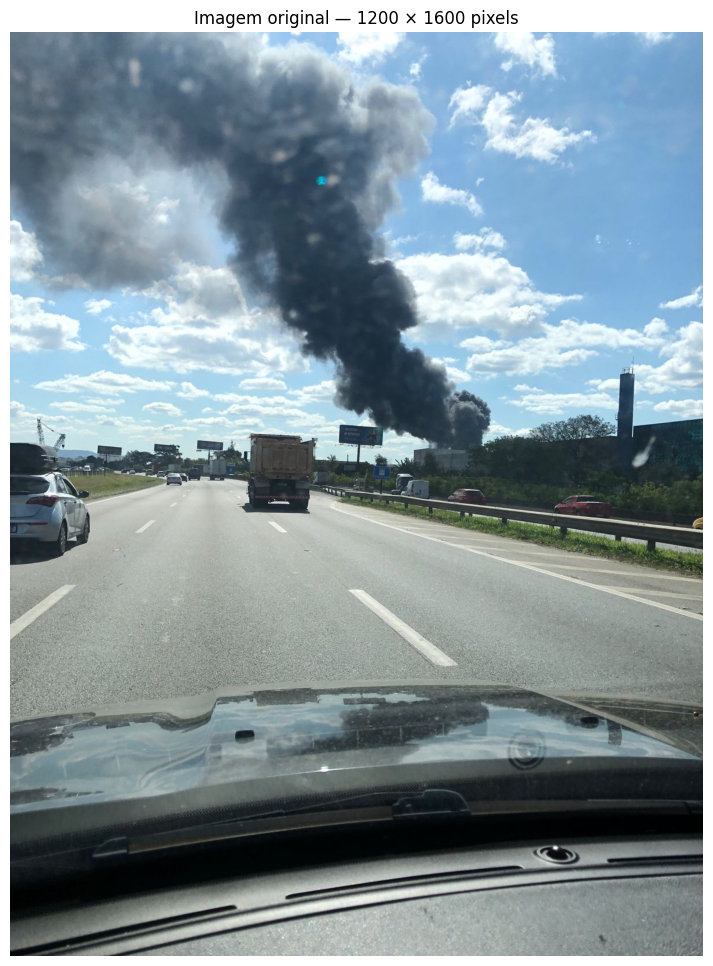

Arquivo carregado: pluma (3).jpeg


In [29]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt

# Selecionar e enviar a imagem
arquivos = files.upload()
imagem_path = next(iter(arquivos))

# Abrir e converter de BGR para RGB
imagem_bgr = cv2.imread(imagem_path)

if imagem_bgr is None:
    raise ValueError(f"Não foi possível abrir a imagem: {imagem_path}")

imagem = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)

# Exibir
plt.figure(figsize=(9, 12))
plt.imshow(imagem)
plt.axis("off")
plt.title(
    f"Imagem original — "
    f"{imagem.shape[1]} × {imagem.shape[0]} pixels"
)
plt.show()

print("Arquivo carregado:", imagem_path)

In [30]:
caixa_pluma = [0, 0, 860, 740]

print("Caixa delimitadora:", caixa_pluma)

Caixa delimitadora: [0, 0, 860, 740]


In [31]:
pontos_positivos = [
    [180, 170],  # fumaça espalhada na parte superior esquerda
    [525, 260],  # coluna escura superior
    [570, 460],  # centro da coluna
    [660, 590],  # parte inferior da pluma
    [775, 680]   # região próxima à origem
]

In [32]:
pontos_negativos = [
    [770, 150],  # céu azul
    [745, 385],  # nuvem clara à direita
    [270, 430],  # nuvem clara à esquerda
    [930, 520],  # céu/nuvens
    [1050, 650]  # estrutura à direita
]

In [33]:
experimentos = [
    {
        "nome": "1 — Somente caixa",
        "bboxes": caixa_pluma,
        "points": None,
        "labels": None
    },
    {
        "nome": "2 — Somente pontos positivos",
        "bboxes": None,
        "points": pontos_positivos,
        "labels": [1, 1, 1, 1, 1]
    },
    {
        "nome": "3 — Caixa, positivos e negativos",
        "bboxes": caixa_pluma,
        "points": pontos_positivos + pontos_negativos,
        "labels": [
            1, 1, 1, 1, 1,  # positivos
            0, 0, 0, 0, 0   # negativos
        ]
    }
]

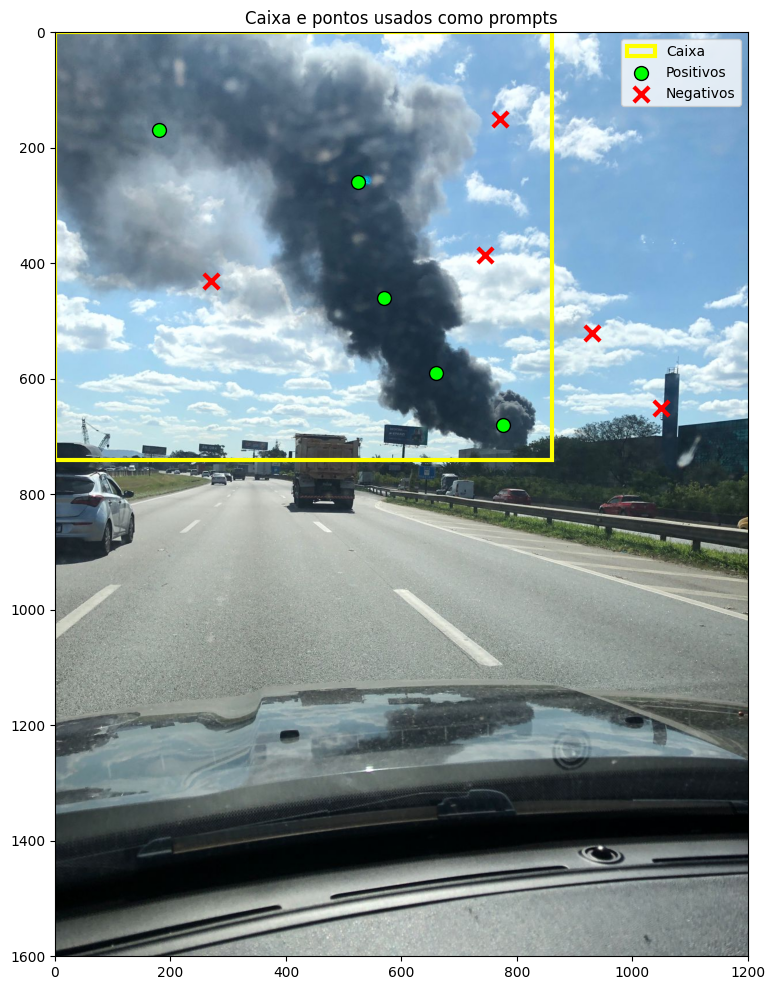

In [34]:
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

imagem_bgr = cv2.imread(imagem_path)
imagem = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(figsize=(9, 12))
ax.imshow(imagem)

# Caixa
x1, y1, x2, y2 = caixa_pluma
retangulo = Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    linewidth=3,
    edgecolor="yellow",
    facecolor="none",
    label="Caixa"
)
ax.add_patch(retangulo)

# Pontos positivos
positivos_x = [p[0] for p in pontos_positivos]
positivos_y = [p[1] for p in pontos_positivos]

ax.scatter(
    positivos_x,
    positivos_y,
    c="lime",
    s=100,
    marker="o",
    edgecolors="black",
    label="Positivos"
)

# Pontos negativos
negativos_x = [p[0] for p in pontos_negativos]
negativos_y = [p[1] for p in pontos_negativos]

ax.scatter(
    negativos_x,
    negativos_y,
    c="red",
    s=120,
    marker="x",
    linewidths=3,
    label="Negativos"
)

ax.set_xlim(0, imagem.shape[1])
ax.set_ylim(imagem.shape[0], 0)
ax.legend()
ax.set_title("Caixa e pontos usados como prompts")
plt.show()

Resultado inicial do SAM

In [35]:
!pip install -q ultralytics

In [36]:
from ultralytics import SAM

model = SAM("sam2.1_b.pt")

In [37]:
experimentos = [
    {
        "nome": "1 — Somente caixa",
        "bboxes": caixa_pluma,
        "points": None,
        "labels": None
    },
    {
        "nome": "2 — Somente pontos positivos",
        "bboxes": None,

        # Uma lista externa indica um único objeto
        "points": [pontos_positivos],
        "labels": [[1] * len(pontos_positivos)]
    },
    {
        "nome": "3 — Caixa, positivos e negativos",
        "bboxes": caixa_pluma,

        # Todos os pontos orientam a segmentação da mesma pluma
        "points": [
            pontos_positivos + pontos_negativos
        ],
        "labels": [[
            *([1] * len(pontos_positivos)),
            *([0] * len(pontos_negativos))
        ]]
    }
]

In [38]:
import cv2
import numpy as np

def executar_experimento(config):
    argumentos = {}

    if config["bboxes"] is not None:
        argumentos["bboxes"] = config["bboxes"]

    if config["points"] is not None:
        argumentos["points"] = config["points"]
        argumentos["labels"] = config["labels"]

    resultado = model(
        imagem_path,
        verbose=False,
        **argumentos
    )[0]

    if resultado.masks is None:
        return None

    mascara = resultado.masks.data[0].cpu().numpy()

    mascara = cv2.resize(
        mascara.astype(np.float32),
        (imagem.shape[1], imagem.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    return mascara > 0.5

In [39]:
resultados = {}

for configuracao in experimentos:
    nome = configuracao["nome"]
    print("Executando:", nome)

    resultados[nome] = executar_experimento(configuracao)

print("Experimentos concluídos.")

Executando: 1 — Somente caixa
Executando: 2 — Somente pontos positivos
Executando: 3 — Caixa, positivos e negativos
Experimentos concluídos.


In [40]:
def criar_sobreposicao(imagem, mascara):
    sobreposicao = imagem.copy()
    cor_fumaca = np.array([255, 40, 30])

    sobreposicao[mascara] = (
        0.55 * sobreposicao[mascara]
        + 0.45 * cor_fumaca
    ).astype(np.uint8)

    return sobreposicao

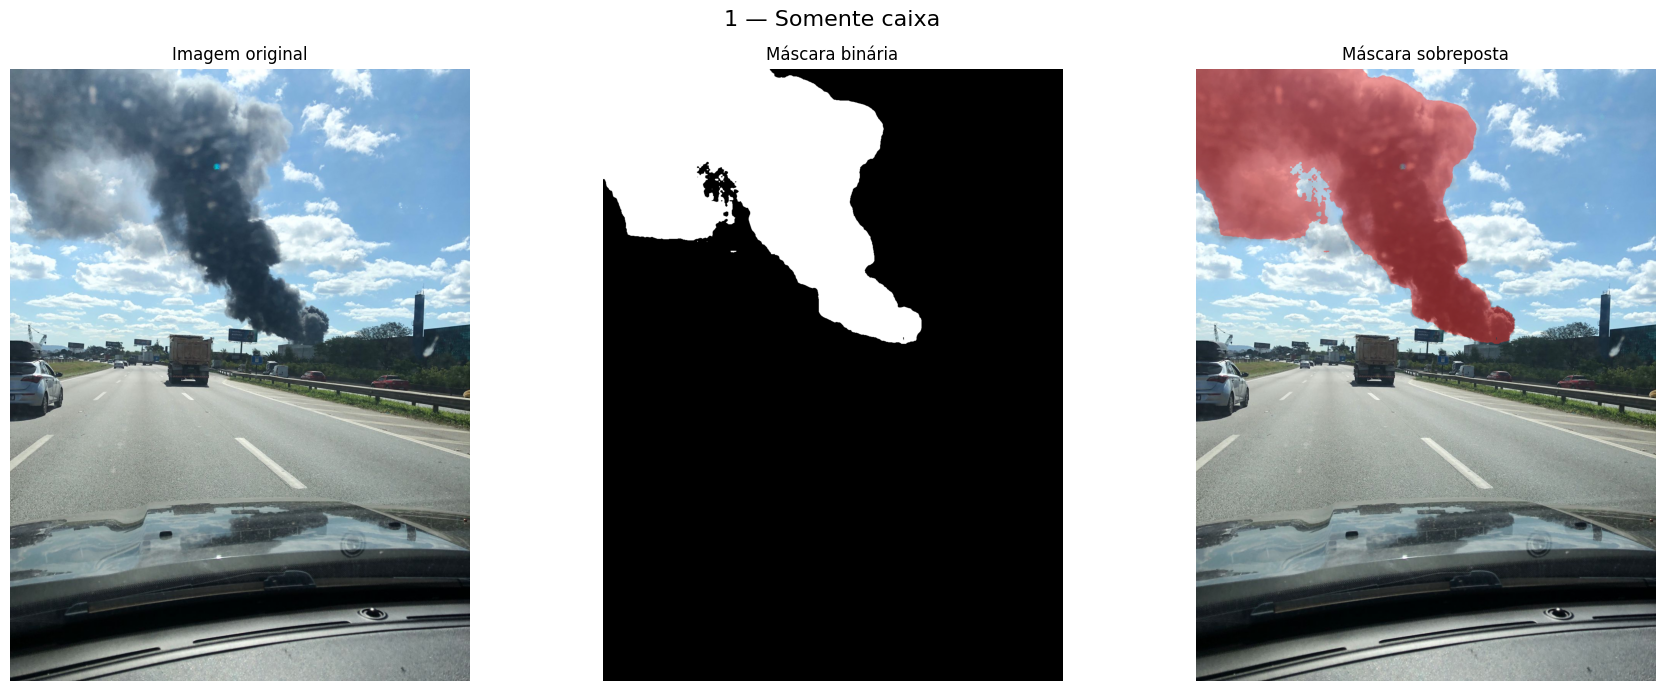

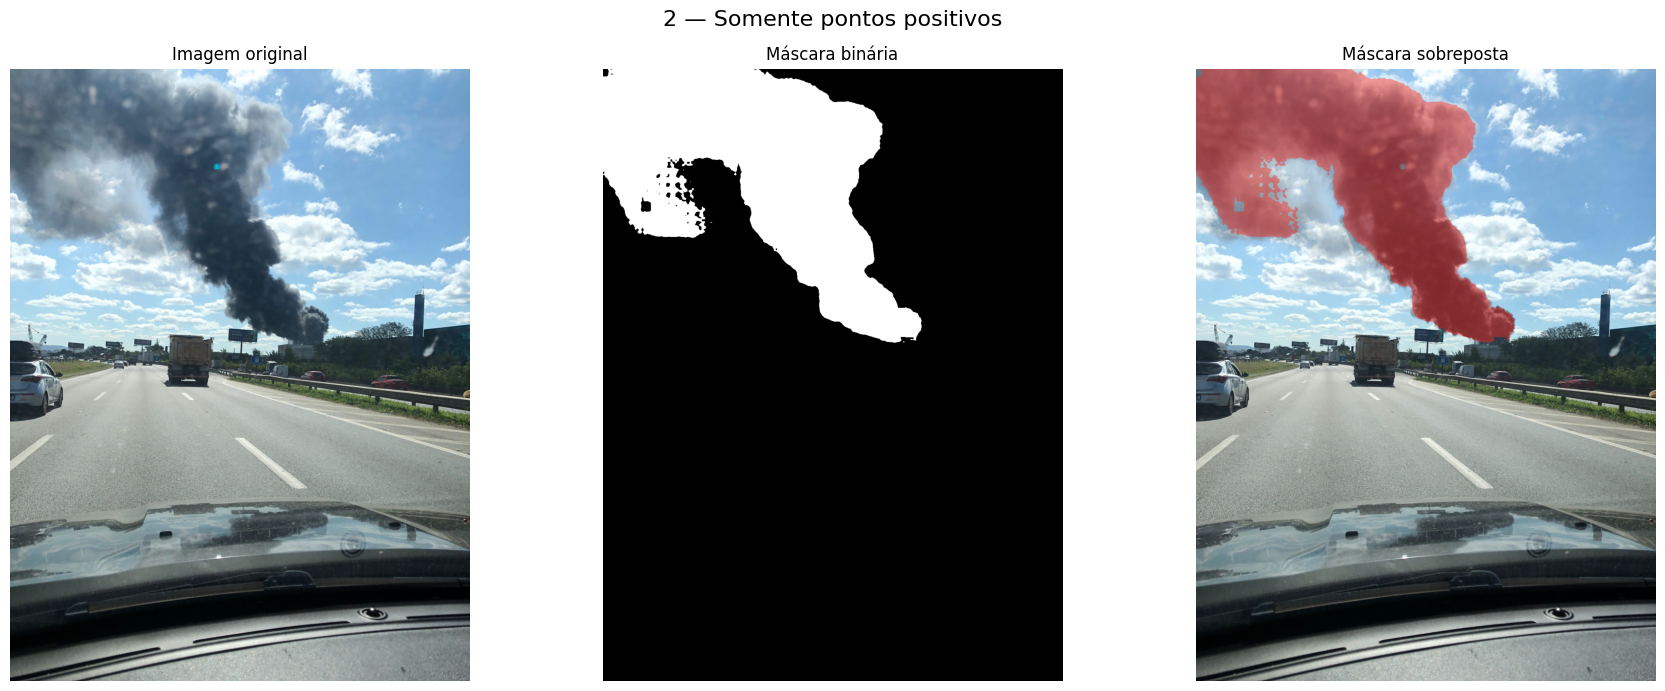

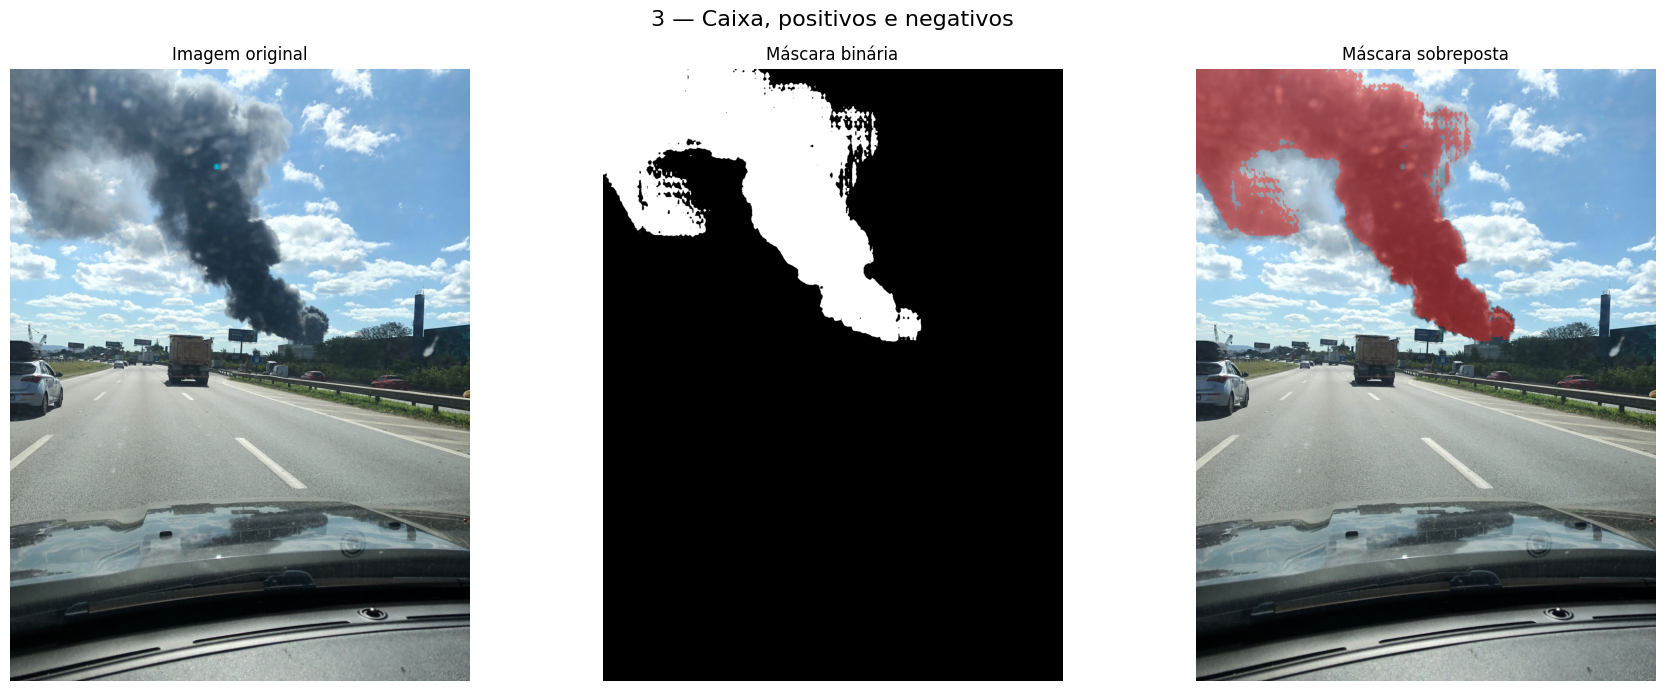

In [41]:
for nome, mascara in resultados.items():
    if mascara is None:
        print(f"Nenhuma máscara gerada em: {nome}")
        continue

    sobreposicao = criar_sobreposicao(imagem, mascara)

    fig, axes = plt.subplots(1, 3, figsize=(18, 7))

    axes[0].imshow(imagem)
    axes[0].set_title("Imagem original")

    axes[1].imshow(mascara, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Máscara binária")

    axes[2].imshow(sobreposicao)
    axes[2].set_title("Máscara sobreposta")

    for ax in axes:
        ax.axis("off")

    fig.suptitle(nome, fontsize=16)
    plt.tight_layout()
    plt.show()

In [42]:
avaliacao = []

for nome, mascara in resultados.items():
    if mascara is None:
        continue

    area_pixels = int(mascara.sum())
    percentual_imagem = 100 * mascara.mean()

    numero_componentes, _ = cv2.connectedComponents(
        mascara.astype(np.uint8)
    )

    avaliacao.append({
        "Configuração": nome,
        "Área da máscara (pixels)": area_pixels,
        "Área da imagem (%)": round(percentual_imagem, 2),
        "Regiões desconectadas": numero_componentes - 1
    })

tabela_avaliacao = pd.DataFrame(avaliacao)
tabela_avaliacao

,Configuração,Área da máscara (pixels),Área da imagem (%),Regiões desconectadas
0,1 — Somente caixa,331772,17.28,12
1,2 — Somente pontos positivos,305921,15.93,7
2,"3 — Caixa, positivos e negativos",274942,14.32,33


Comparação dos resultados

### Comparação qualitativa

| Configuração | Cobertura da pluma | Inclusões indevidas | Partes excluídas | Avaliação |
|---|---|---|---|---|
| Somente caixa | Cobriu a maior parte da pluma | Possível inclusão de fumaça muito clara ou nuvens próximas | Pequenas falhas causadas por reflexos | Resultado mais contínuo |
| Pontos positivos | Cobriu a coluna principal | Apresentou pequenas regiões irregulares | Algumas áreas claras não foram incluídas | Resultado semelhante ao da caixa |
| Caixa, positivos e negativos | Cobriu a região escura principal | Reduziu algumas regiões externas | Criou buracos na máscara | Os pontos negativos também atingiram regiões ambíguas |

Discussão das dificuldades

A imagem apresenta alto contraste entre a fumaça escura e o céu, o que
facilita a identificação da parte central da pluma. Entretanto, suas bordas
são difusas e algumas partes da fumaça são cinza-claro, tornando-se
visualmente semelhantes às nuvens.

Também existem manchas e reflexos no para-brisa. Esses elementos produziram
pequenas falhas na máscara. Os pontos negativos ajudaram a indicar regiões
que não pertencem à pluma, mas alguns foram colocados próximos de áreas
ambíguas. Como consequência, o terceiro experimento apresentou buracos e
maior fragmentação.

O experimento com somente a caixa delimitadora produziu o resultado visual
mais contínuo. Isso mostra que o aumento do número de prompts não garante
melhoria quando as fronteiras do objeto são pouco definidas.

 Conclusões

A configuração com somente a caixa apresentou a maior cobertura da pluma,
ocupando 17,28% da imagem. A configuração com pontos positivos apresentou
menor área e o menor número de regiões desconectadas, indicando menor
fragmentação. A combinação de caixa, pontos positivos e negativos resultou
na menor área e em 33 regiões desconectadas, mostrando que os pontos
negativos fragmentaram excessivamente a segmentação.

A análise numérica deve ser combinada com a observação visual, pois uma
máscara maior não é necessariamente mais correta e um número menor de
componentes não garante que toda a fumaça tenha sido incluída.